# **Task1: Misspecified simulation with ridge (set $c = 10$, dense $β^{∗}$).**

## I. Environment setup and imports.
Import required tool functions from `/src` and other packages for graphics, initialize the simulation configurations, then create a folder for saving the results.

In [1]:
import os
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import sys
from pathlib import Path

# import all necessary functions and default configurations from /src
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Reload local modules so an active notebook kernel picks up source changes.
import src.config
import src.models
importlib.reload(src.config)
importlib.reload(src.models)
import src
importlib.reload(src)
import src.plotting as plot
importlib.reload(plot)

from src import (
    generate_dgp_data, get_observed_block, fit_ridge_path, eval_oos_performance,
    DGP_DEFAULTS, CQ_GRID, Z_GRID, N_RUNS, SEED,
    FIG_DIR
)

# ensure the image saving path exists
os.makedirs(FIG_DIR, exist_ok=True)

## II. Monte Carlo simulations.
This section performs Monte Carlo simulations (e.g., $N=20$ runs) across varying levels of observed complexity ($c \cdot q$) and shrinkage penalty ($z$). Averaging across multiple runs reduces finite-sample noise and recovers the smooth asymptotic curves predicted by KMZ.

In [2]:
n_runs = N_RUNS # Number of Monte Carlo repetitions (from 20 to 50)
T_tr = DGP_DEFAULTS['T_train']
c_dgp = DGP_DEFAULTS['c']
P_total = int(c_dgp * T_tr)

# Data containers for storing metrics across Monte Carlo runs
metrics_names = ['r2_paper', 'exp_return', 'sharpe', 'beta_norm_sq']
results = {m: np.zeros((n_runs, len(CQ_GRID), len(Z_GRID))) for m in metrics_names}

print("Running Monte Carlo simulations for Task 1...\n")

for run in tqdm(range(n_runs)):
    # Generate datasets and apply random permutations
    seed = SEED + run
    S_tr, R_tr, S_te, R_te, beta_star, P = generate_dgp_data(**DGP_DEFAULTS, seed=seed)
    rng = np.random.default_rng(seed)
    permuted_indices = rng.permutation(P_total)

    # Iterate over the observed complexity grid (cq)
    for i, cq in enumerate(CQ_GRID):
        P1 = int(round(cq * T_tr))
        X_tr, X_te = get_observed_block(S_tr, S_te, P1, permuted_indices)
        beta_hats = fit_ridge_path(X_tr, R_tr, Z_GRID)
        R_hat_grid = X_te @ beta_hats.T

        # Iterate over the shrinkage penalty grid (z)
        for j, z in enumerate(Z_GRID):
            R_hat = R_hat_grid[:, j]
            R_pi = R_hat * R_te

            results['r2_paper'][run, i, j] = 1 - np.mean((R_te - R_hat) ** 2) / np.mean(R_te ** 2)
            results['exp_return'][run, i, j] = np.mean(R_pi)
            second_moment = np.mean(R_pi ** 2)
            results['sharpe'][run, i, j] = (
                np.mean(R_pi) / np.sqrt(second_moment) if second_moment > 1e-12 else 0.0
            )
            results['beta_norm_sq'][run, i, j] = np.sum(beta_hats[j] ** 2)

# Compute Monte Carlo expectations (average across runs)
avg_results = {m: np.mean(results[m], axis=0) for m in metrics_names}

print("\nSimulation finished successfully!")

Running Monte Carlo simulations for Task 1...



100%|██████████| 20/20 [01:10<00:00,  3.54s/it]


Simulation finished successfully!


## III. Visualize and export OOS performance curves.
We plot the four key evaluation metrics against observed complexity ($c \cdot q$) for representative shrinkage levels ($z$). The vertical dashed line at $c \cdot q=1$ indicates the interpolation threshold where $P_1 = T_{train}$.

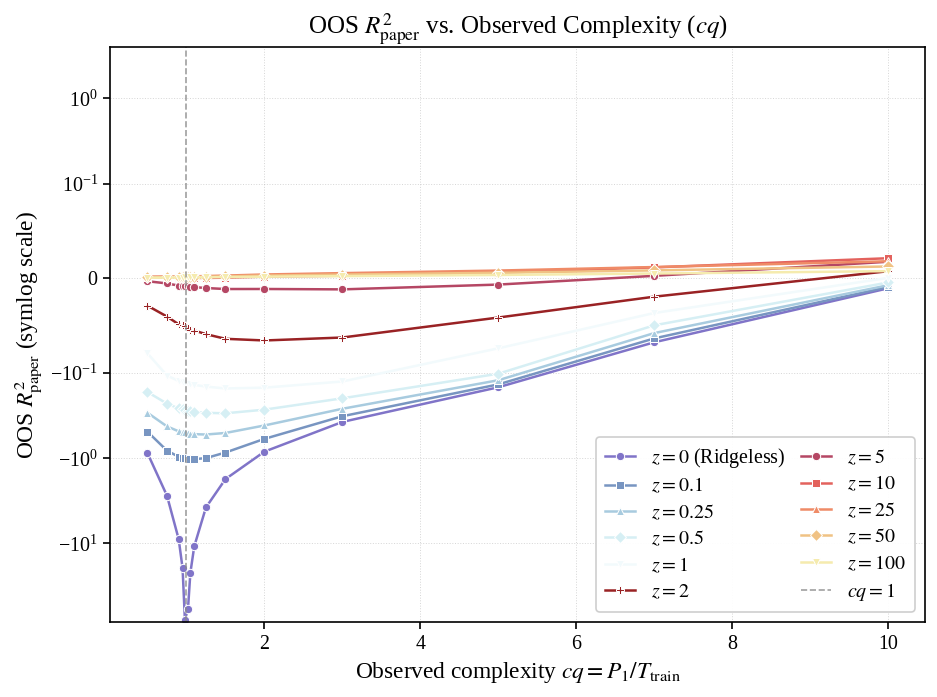

In [12]:
# Figure 1: OOS R2_paper
fig, ax = plt.subplots(figsize=plot.FIGSIZE)
plot.plot_metric_grid(ax, CQ_GRID, avg_results, Z_GRID, 'r2_paper', ridgeless_label=True)
plot.add_interpolation_marker(ax, r'$cq = 1$')
ax.set_yscale('symlog', linthresh=0.1)
ax.grid(True, which='both')
plot.finalize_and_save(
    fig, ax,
    title=r"OOS $R^2_{\mathrm{paper}}$ vs. Observed Complexity ($cq$)",
    xlabel=r"Observed complexity $cq=P_1/T_{\mathrm{train}}$",
    ylabel=r"OOS $R^2_{\mathrm{paper}}$ (symlog scale)",
    savepath=f"{FIG_DIR}/task1_r2_paper.{plot.FIG_FORMAT}",
    loc='lower right'
)
plt.show()
plt.show()

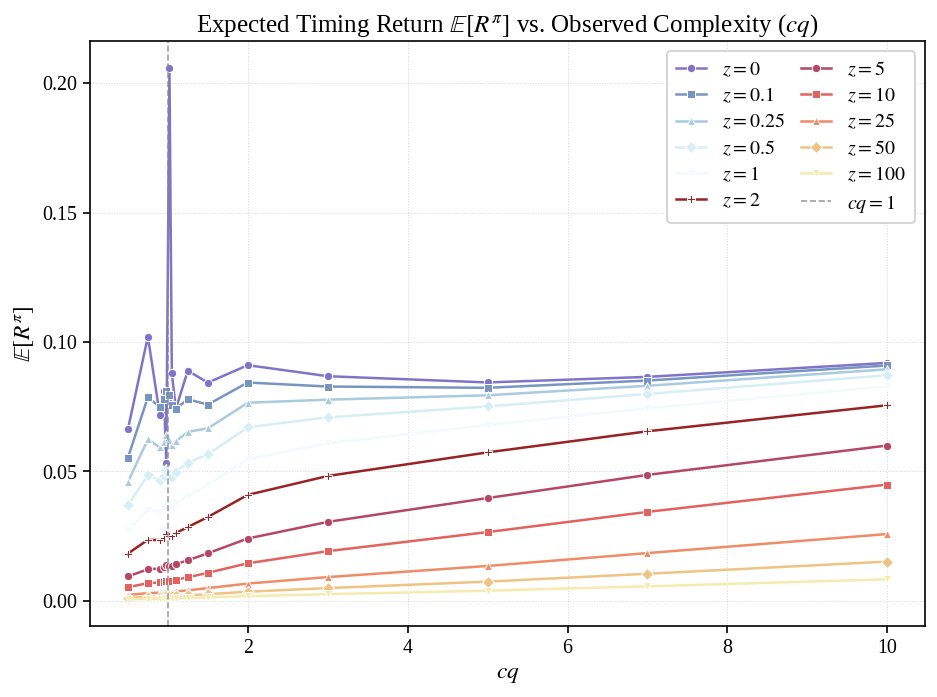

In [4]:
# Figure 2: Expected Timing Return
fig, ax = plt.subplots(figsize=plot.FIGSIZE)
plot.plot_metric_grid(ax, CQ_GRID, avg_results, Z_GRID, 'exp_return')
plot.add_interpolation_marker(ax)
plot.finalize_and_save(
    fig, ax,
    title=r"Expected Timing Return $\mathbb{E}[R^{\pi}]$ vs. Observed Complexity ($cq$)",
    xlabel=r"$cq$",
    ylabel=r"$\mathbb{E}[R^{\pi}]$",
    savepath=f"{FIG_DIR}/task1_expected_return.{plot.FIG_FORMAT}",
)
plt.show()

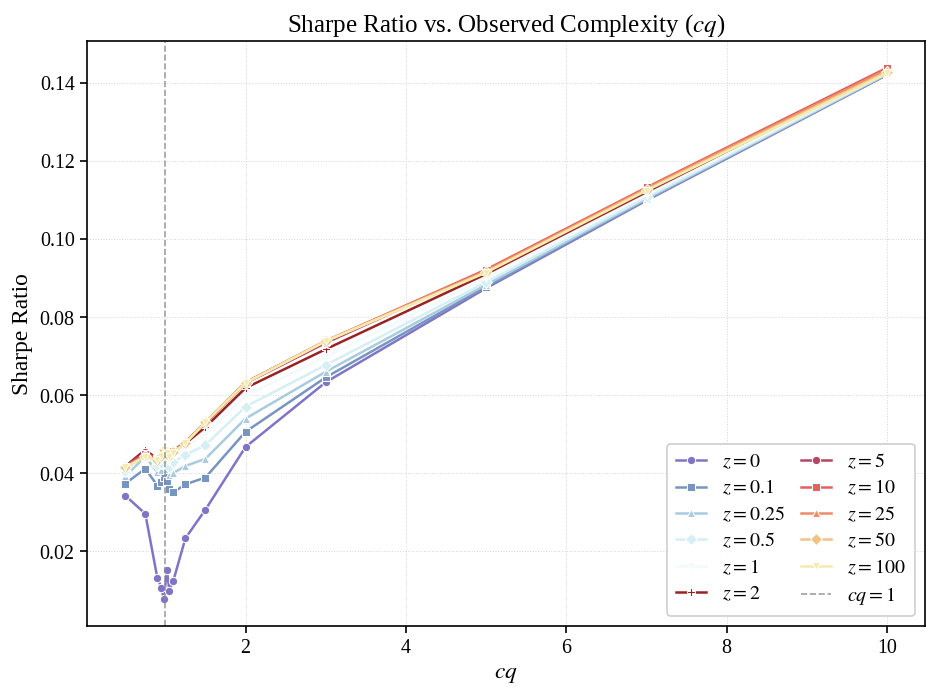

In [5]:
# Figure 3: Sharpe Ratio
fig, ax = plt.subplots(figsize=plot.FIGSIZE)
plot.plot_metric_grid(ax, CQ_GRID, avg_results, Z_GRID, 'sharpe')
plot.add_interpolation_marker(ax)
plot.finalize_and_save(
    fig, ax,
    title=r"Sharpe Ratio vs. Observed Complexity ($cq$)",
    xlabel=r"$cq$",
    ylabel=r"Sharpe Ratio",
    savepath=f"{FIG_DIR}/task1_sharpe_ratio.{plot.FIG_FORMAT}",
    loc='lower right'
)
plt.show()

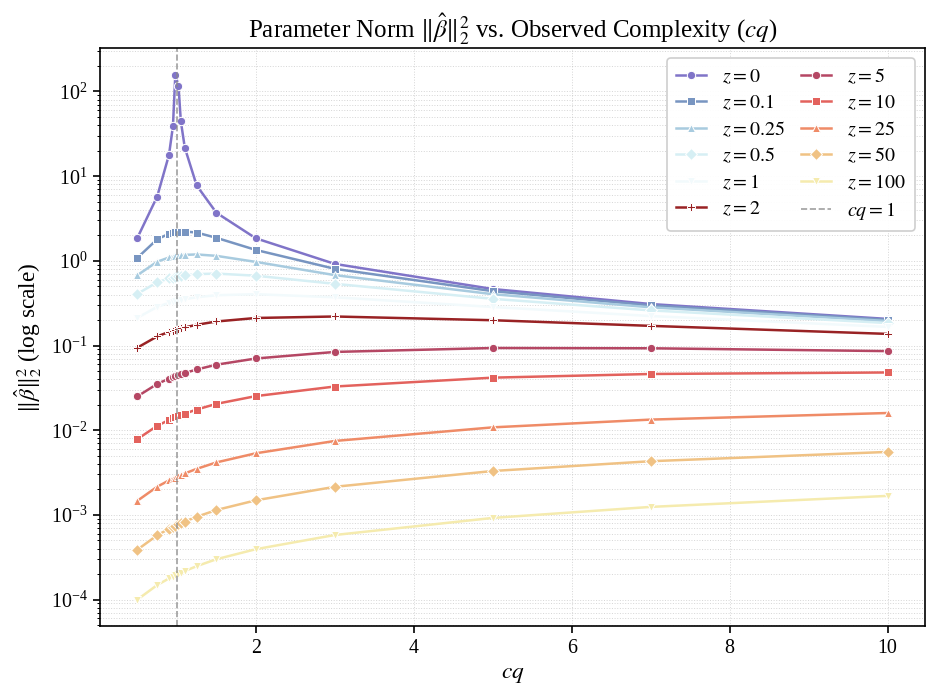

In [13]:
# Figure 4: Parameter Norm Squared ||beta||^2 (Log Scale)
fig, ax = plt.subplots(figsize=plot.FIGSIZE)
plot.plot_metric_grid(ax, CQ_GRID, avg_results, Z_GRID, 'beta_norm_sq')
plot.add_interpolation_marker(ax)
plot.finalize_and_save(
    fig, ax,
    title=r"Parameter Norm $\|\hat{\beta}\|_2^2$ vs. Observed Complexity ($cq$)",
    xlabel=r"$cq$",
    ylabel=r"$\|\hat{\beta}\|_2^2$ (log scale)",
    yscale='log',
    savepath=f"{FIG_DIR}/task1_beta_norm.{plot.FIG_FORMAT}",
)
plt.show()